# 8. 영상 스티칭 (Image Stitching)

설명과 코드 셀을 위에서부터 실행한다. MD와 IPYNB는 같은 학습 순서이며 결과 이미지도 포함한다.

- ZIP을 풀고 `Stitching_Notes` 폴더에서 노트북을 연다.
- 필요한 패키지: `%pip install opencv-python numpy matplotlib`
- 작업 폴더가 다르면 첫 셀의 ROOT를 바꾼다. 옵시디언에는 MD와 assets 폴더를 함께 넣는다.

## 8.1 영상 스티칭의 원리

- 겹치는 사진에서 같은 위치를 찾고, 좌표를 맞춘 뒤 한 장으로 합친다.
- 옆으로 나란히 붙이는 것만으로는 겹친 물체가 맞지 않는다.
- **대응점 찾기 → 변환 추정 → 워핑 → 합성 → 블렌딩** 순서로 진행한다.
- 정렬은 위치를 맞추는 작업, 블렌딩은 겹치는 부분의 색을 섞는 작업이다.
- 블렌딩만으로 잘못된 정렬이나 움직이는 물체의 겹침을 해결할 수는 없다.

이번에는 같은 레나에서 겹치는 두 영역을 잘라 통제 실험을 한다. 실제 서로 다른 카메라 촬영이 아니므로 시차·움직임·렌즈 왜곡 등의 어려움이 생략된다. 원본 밖의 새로운 장면을 생성하는 실험도 아니다.

### 셀 1. 준비와 두 입력 생성

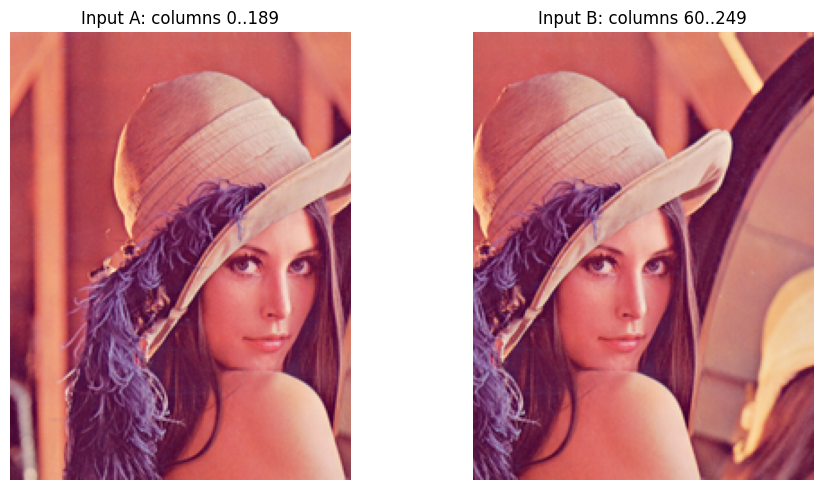

OpenCV: 5.0.0


In [1]:
# 셀 1: 겹치는 두 입력 준비
# 레나를 겹치게 자른 합성 입력이며 B의 좌표를 A로 옮기는 정답은 x 방향 +60이다.

# Path는 운영체제에 맞게 파일 경로를 조합하는 데 사용한다.
from pathlib import Path
import json
# OpenCV는 영상 처리, NumPy는 배열 계산, Matplotlib은 결과 시각화에 사용한다.
import cv2
import numpy as np
import matplotlib.pyplot as plt
# 현재 작업 폴더를 기준으로 assets를 찾는다. 노트북은 각 장의 폴더에서 실행한다.
ROOT=Path.cwd()
ASSETS=ROOT/'assets'
assert (ASSETS/'Lenna.png').is_file(), 'ROOT를 확인하세요.'
# 파일을 바이트 배열로 읽어 디코딩한다. IMREAD_COLOR의 결과는 BGR 순서다.
original=cv2.imdecode(np.fromfile(ASSETS/'Lenna.png',np.uint8),cv2.IMREAD_COLOR)
assert original is not None
A=original[:,:190].copy()
B=original[:,60:].copy()
# 합성 입력의 정답 좌표 관계 B -> A. 추정에는 사용하지 않습니다.
H_true=np.array([[1,0,60],[0,1,0],[0,0,1]],np.float64)

# 비교 그림의 배치를 통일하고, 영상 또는 결과 배열을 화면에 표시한다.
def show(items,name):
    fig,axs=plt.subplots(1,len(items),figsize=(5*len(items),5),squeeze=False)
    for ax,(title,img) in zip(axs.flat,items):
        if img.ndim==2:ax.imshow(img,cmap='gray',vmin=0,vmax=255)
        else:ax.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
        ax.set_title(title);ax.axis('off')
    fig.tight_layout();fig.savefig(ASSETS/name,dpi=140)
    plt.show();plt.close(fig)
show([('Input A: columns 0..189',A),('Input B: columns 60..249',B)],'inputs.png')
print('OpenCV:',cv2.__version__)

## 8.2 특징점 검출과 매칭 활용

- ORB 특징점과 이진 기술자를 계산한다.
- 해밍 거리로 각 B 특징점에 대한 A의 두 후보를 찾는다.
- 비율 검사로 애매한 대응을 줄인다.
- 이번 방향은 **B 좌표를 A 좌표로 변환**하는 것이다. query는 B, train은 A다.

### 셀 2. ORB와 비율 검사

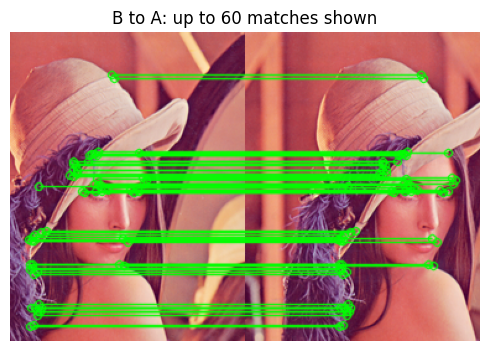

특징점 A/B: 1466 1416 비율 검사 통과: 743


In [2]:
# 셀 2: B에서 A로 특징점 매칭
# B의 기술자를 질의하여 A의 두 최근접 후보를 비교하고 비율 검사로 대응을 고른다.

# nfeatures는 유지할 특징점 수의 목표 상한이며, 검출 수는 입력의 무늬와 다른 설정에도 좌우된다.
orb=cv2.ORB_create(nfeatures=1500,edgeThreshold=10,fastThreshold=10)
gA=cv2.cvtColor(A,cv2.COLOR_BGR2GRAY);gB=cv2.cvtColor(B,cv2.COLOR_BGR2GRAY)
# 위치·방향·스케일을 담은 키포인트와 매칭에 사용할 기술자를 함께 구한다.
kA,dA=orb.detectAndCompute(gA,None);kB,dB=orb.detectAndCompute(gB,None)
if dA is None or dB is None or len(dA)<2:raise RuntimeError('기술자가 부족합니다.')
# 질의 기술자마다 가까운 후보 두 개를 찾는다. 후보 수가 부족할 수 있어 길이를 확인한다.
pairs=cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(dB,dA,k=2)
good=[p[0] for p in pairs if len(p)==2 and p[0].distance<.75*p[1].distance]
print('특징점 A/B:',len(kA),len(kB),'비율 검사 통과:',len(good))
matched=cv2.drawMatches(B,kB,A,kA,sorted(good,key=lambda m:m.distance)[:60],None,
                       matchColor=(0,255,0),flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show([('B to A: up to 60 matches shown',matched)],'matches.png')

## 8.3 호모그래피 추정

$$
\lambda\begin{bmatrix}x_A\\y_A\\1\end{bmatrix}
=H_{B\to A}\begin{bmatrix}x_B\\y_B\\1\end{bmatrix}
$$

- 호모그래피는 좌표를 옮기는 3×3 행렬이며 전체 배율을 제외하면 자유도가 8이다.
- 최소 4쌍의 일반 위치 대응이 필요하다. 한 직선에 몰린 점 등은 적합하지 않다.
- RANSAC으로 하나의 모델과 일치하는 대응을 찾는다.
- 인라이어는 선택한 모델과 임계값에 맞는 대응이지 절대적인 정답 판정은 아니다.
- 평면 장면이나 적절한 순수 카메라 회전 상황에는 유용하지만, 깊이가 다양한 장면에서 카메라가 이동하면 하나의 호모그래피로 맞지 않을 수 있다.

### 셀 3. RANSAC과 정답 변환 비교

In [3]:
# 셀 3: B → A 호모그래피 추정
# RANSAC 인라이어를 구하고 별도 격자에서 알려진 이동 변환과의 차이를 확인한다.

if len(good)<4:raise RuntimeError('대응점이 부족합니다.')
# 질의 영상의 키포인트 좌표를 (N,1,2) 형태로 모아 변환 추정의 출발점으로 사용한다.
pB=np.float32([kB[m.queryIdx].pt for m in good]).reshape(-1,1,2)
# trainIdx에 해당하는 대상 영상 좌표를 같은 대응 순서로 모은다.
pA=np.float32([kA[m.trainIdx].pt for m in good]).reshape(-1,1,2)
cv2.setRNGSeed(42)
# RANSAC의 허용 재투영 오차는 3픽셀이며, 반환 mask는 추정 모델의 인라이어 표시다.
# maxIters=5000은 반복 상한, confidence=0.995는 RANSAC 모델 탐색의 목표 신뢰 수준이다.
H,mask=cv2.findHomography(pB,pA,cv2.RANSAC,3.0,maxIters=5000,confidence=.995)
if H is None or mask is None or not np.isfinite(H).all():raise RuntimeError('호모그래피 추정 실패')
# OpenCV의 0/1 인라이어 표시를 1차원 불리언 배열로 바꾼다.
inlier=mask.ravel().astype(bool)
if inlier.sum()<4:raise RuntimeError('인라이어 부족')
xx,yy=np.meshgrid(np.linspace(10,B.shape[1]-11,8),np.linspace(10,B.shape[0]-11,8))
grid=np.stack([xx.ravel(),yy.ravel()],axis=1).astype(np.float32).reshape(-1,1,2)
err=np.linalg.norm(cv2.perspectiveTransform(grid,H)-cv2.perspectiveTransform(grid,H_true),axis=2)
print('인라이어:',int(inlier.sum()),'격자점 중앙 오차:',float(np.median(err)),'px')
assert np.median(err)<3, '통제 실험의 변환 오차가 큽니다.'
print('H (B -> A):\n',H)

인라이어: 709 격자점 중앙 오차: 0.1273762285709381 px
H (B -> A):
 [[ 9.93428839e-01 -3.33071424e-03  6.04338467e+01]
 [-1.11065262e-03  9.92509075e-01  5.23609914e-01]
 [-8.09422944e-06 -2.41626995e-05  1.00000000e+00]]


## 8.4 영상 워핑과 정렬

### 음수 좌표도 들어갈 캔버스 만들기

- 변환한 B의 모서리와 A의 모서리를 모두 감싸는 범위를 구한다.
- 최소 좌표가 음수일 수도 있으므로 모든 좌표를 캔버스 안으로 옮기는 이동 행렬을 곱한다.

$$
T=\begin{bmatrix}1&0&-x_{\min}\\0&1&-y_{\min}\\0&0&1\end{bmatrix},\qquad
H_{B\to canvas}=TH_{B\to A}
$$

A에는 T, B에는 TH를 적용한다. 곱셈 순서를 바꾸면 의미가 달라진다.

`warpPerspective()`에 기본 설정으로 입력→출력 변환 행렬을 주면 내부에서 역방향으로 픽셀을 찾아 보간한다. 이 실습은 `WARP_INVERSE_MAP`을 지정하지 않는다.

### 셀 4. 캔버스 크기 계산

In [4]:
# 셀 4: 합성 캔버스 계산
# 변환된 모서리를 모두 포함하는 크기와 좌표 이동 행렬 T를 계산한다.

def corners(img):
    # shape는 (높이, 너비) 순서다. 좌표 (x, y)로 읽을 때는 배열 인덱스 [y, x]와 구분한다.
    h,w=img.shape[:2]
    return np.float32([[0,0],[w-1,0],[w-1,h-1],[0,h-1]]).reshape(-1,1,2)
# 분모가 영상 내부에서 0을 가로지르는 극단적 변환을 거부합니다.
cb=corners(B).reshape(-1,2)
den=cb@H[2,:2]+H[2,2]
if not (np.all(den>1e-6) or np.all(den<-1e-6)):
    raise RuntimeError('영상 내부에서 원근 변환이 발산할 수 있습니다.')
all_corners=np.concatenate([corners(A),cv2.perspectiveTransform(corners(B),H)],axis=0).reshape(-1,2)
xmin,ymin=np.floor(all_corners.min(axis=0)).astype(int)
xmax,ymax=np.ceil(all_corners.max(axis=0)).astype(int)
cw,ch=int(xmax-xmin+1),int(ymax-ymin+1)
if cw<=0 or ch<=0 or cw*ch>4_000_000:raise RuntimeError('비정상적인 캔버스 크기')
# 최소 x·y가 0이 되도록 캔버스 좌표를 이동한다. B의 최종 변환은 T@H이다.
T=np.array([[1,0,-xmin],[0,1,-ymin],[0,0,1]],np.float64)
print('캔버스 너비/높이:',cw,ch)

캔버스 너비/높이: 251 251


### 셀 5. 영상과 유효 영역 마스크 워핑

검정색 픽셀도 실제 영상의 일부일 수 있다. 따라서 `이미지 > 0`으로 유효 영역을 판정하지 않고, 별도의 마스크를 함께 변환한다. 보간 과정에서 경계 밖의 0이 색을 어둡게 만드는 영향을 줄이기 위해 마스크 보간값으로 색을 보정한다.

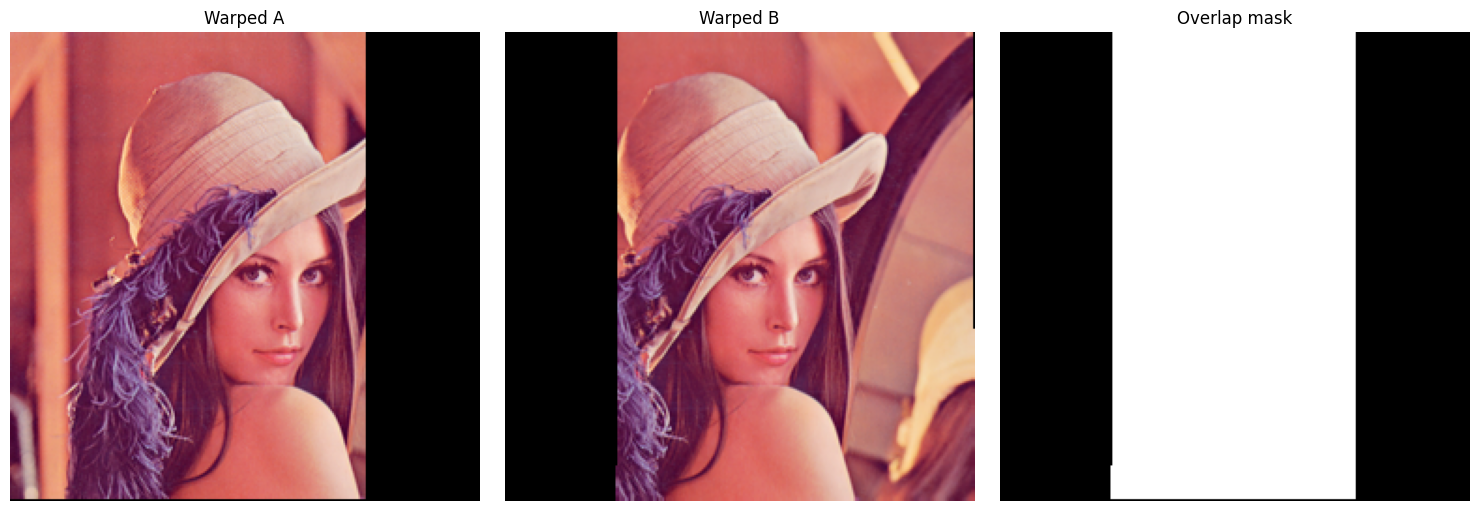

In [5]:
# 셀 5: 워핑과 유효 영역 마스크
# 검정 픽셀도 유효한 영상일 수 있으므로 별도의 support 마스크로 영역을 판단한다.

def warp_with_mask(img,M):
    support=np.ones(img.shape[:2],np.float32)
    # 전부 1인 support를 워핑하여 각 출력 픽셀에 유효 영상이 차지하는 비율을 구한다.
    alpha=cv2.warpPerspective(support,M,(cw,ch),flags=cv2.INTER_LINEAR)
    premul=cv2.warpPerspective(img.astype(np.float32),M,(cw,ch),flags=cv2.INTER_LINEAR)
    valid=alpha>1e-6
    out=np.zeros_like(premul)
    # 경계 보간으로 섞인 검정 배경의 영향을 alpha로 나누어 보정한다.
    out[valid]=premul[valid]/alpha[valid,None]
    return out,valid
wa,ma=warp_with_mask(A,T)
wb,mb=warp_with_mask(B,T@H)
# 합집합은 한 영상이라도 존재하는 곳, 교집합은 두 영상이 겹치는 곳이다.
union=ma|mb;overlap=ma&mb
assert overlap.any()
show([('Warped A',wa.clip(0,255).astype(np.uint8)),
      ('Warped B',wb.clip(0,255).astype(np.uint8)),
      ('Overlap mask',overlap.astype(np.uint8)*255)],'warps.png')

## 8.5 영상 합성과 블렌딩

### 덮어쓰기·평균·페더링

| 방식 | 겹친 영역 처리 | 관찰 |
| :---: | :---: | :---: |
| 덮어쓰기 | B로 교체 | 경계가 갑자기 바뀔 수 있음 |
| 단순 평균 | A와 B를 반씩 혼합 | 밝기 경계가 남거나 오정렬이 이중으로 보일 수 있음 |
| 페더링 | 영상 경계에서 멀수록 큰 가중치 | 경계를 부드럽게 연결 |

$$
C(p)=\frac{w_A(p)A(p)+w_B(p)B(p)}{w_A(p)+w_B(p)}
$$

페더링에서는 유효 영역 경계까지의 거리를 가중치로 사용한다. 한 영상만 있는 곳은 그 영상을 유지하고 둘 다 없는 곳은 비워 둔다.

### 셀 6. 세 합성 방법 비교

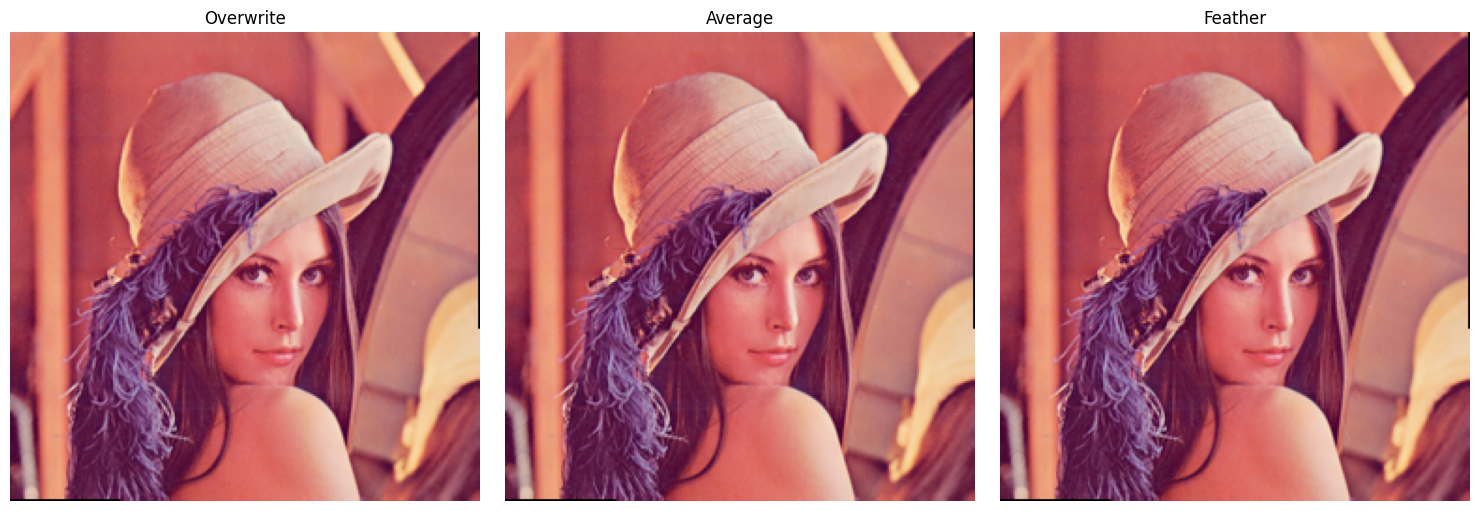

In [6]:
# 셀 6: 덮어쓰기·평균·페더 블렌딩
# 겹치는 영역에서 가중치를 달리해 이음새가 어떻게 달라지는지 비교한다.

# 영상 경계에서 안쪽으로 멀수록 큰 가중치를 주기 위해 거리 변환을 사용한다.
def distance_weight(mask):
    # 마스크 바깥에 0을 한 겹 둘러 가장자리도 배경까지의 거리를 계산할 수 있게 한다.
    padded=np.pad(mask.astype(np.uint8),1)
    return cv2.distanceTransform(padded,cv2.DIST_L2,3)[1:-1,1:-1]
# 두 영상의 내부 거리로 가중치를 만들며 유효하지 않은 영역의 가중치는 0이다.
da=distance_weight(ma);db=distance_weight(mb)
def composites(left,right):
    overwrite=left.copy();overwrite[mb]=right[mb]
    count=ma.astype(np.float32)+mb.astype(np.float32)
    # 유효한 영상의 개수로 나누어 겹침 영역에서는 두 값을 평균낸다.
    average=(left*ma[...,None]+right*mb[...,None])/np.maximum(count[...,None],1)
    # 경계에서의 거리 가중치를 합으로 정규화하여 두 영상의 기여를 부드럽게 섞는다.
    feather=(left*da[...,None]+right*db[...,None])/np.maximum((da+db)[...,None],1e-6)
    return [np.clip(v,0,255).astype(np.uint8) for v in [overwrite,average,feather]]
outputs=composites(wa,wb)
assert np.allclose((da/(np.maximum(da+db,1e-6))+db/(np.maximum(da+db,1e-6)))[union],1,atol=1e-6)
show(list(zip(['Overwrite','Average','Feather'],outputs)),'blend.png')

### 셀 7. 밝기 차이를 추가한 교육용 실험

두 입력은 같은 사진에서 잘랐으므로 색 이음새가 잘 보이지 않을 수 있다. B만 15% 어둡게 만들어 합성 방식 차이를 관찰한다. 기하 모델은 그대로 유지한다. 페더링은 노출 보정 자체가 아니므로 넓은 밝기 변화가 남을 수 있다.

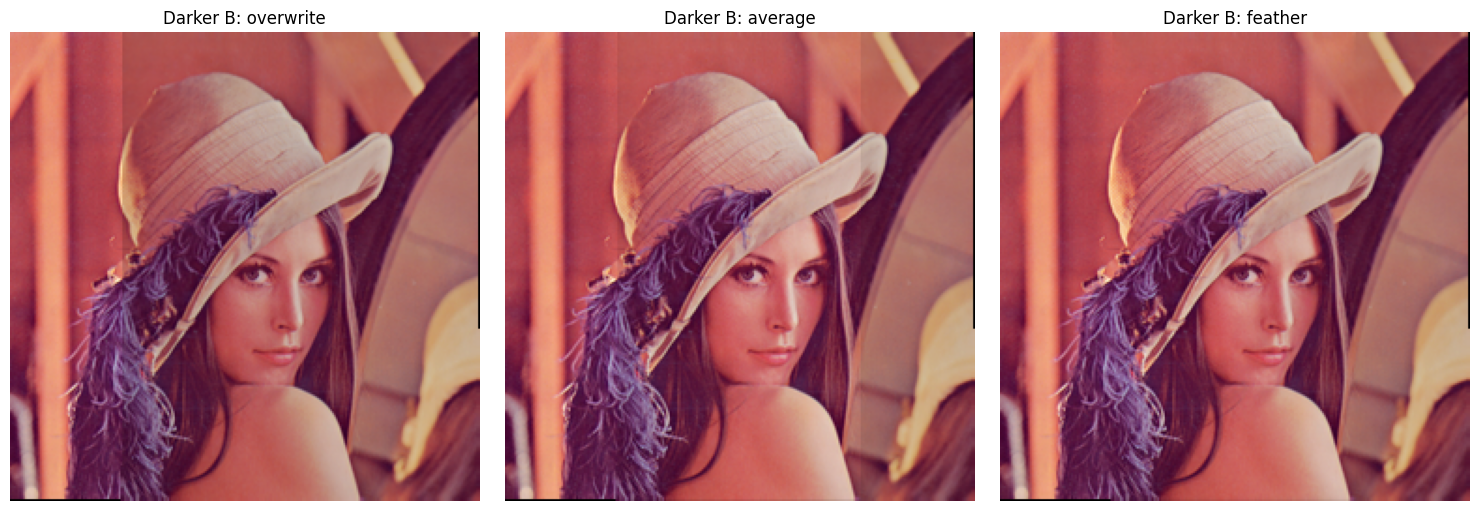

{
  "opencv": "5.0.0",
  "ratio_matches": 743,
  "inliers": 709,
  "grid_median_error_px": 0.1273762285709381,
  "grid_max_error_px": 0.5676870942115784,
  "canvas_width_height": [
    251,
    251
  ],
  "overlap_pixels": 32518
}


In [7]:
# 셀 7: 밝기 차이와 최종 저장
# B를 어둡게 만든 비교를 추가하고, 원래 밝기의 페더 합성 결과를 저장한다.

dark_outputs=composites(wa,wb*.85)
show(list(zip(['Darker B: overwrite','Darker B: average','Darker B: feather'],dark_outputs)),'exposure.png')
# 원래 밝기로 합성한 결과를 저장합니다. 외곽의 완전히 빈 행/열만 제거합니다.
ys,xs=np.where(union)
final=outputs[2][ys.min():ys.max()+1,xs.min():xs.max()+1]
ok,buf=cv2.imencode('.png',final);assert ok
buf.tofile(ASSETS/'stitched_result.png')
summary={'opencv':cv2.__version__,'ratio_matches':len(good),'inliers':int(inlier.sum()),
         'grid_median_error_px':float(np.median(err)),'grid_max_error_px':float(err.max()),
         'canvas_width_height':[cw,ch],'overlap_pixels':int(overlap.sum())}
# 수치 결과를 UTF-8 JSON으로 저장하여 그림과 별도로 확인할 수 있게 한다.
(ROOT/'results.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
# 다시 분석할 수 있도록 계산 배열을 원래 자료형으로 보존한다.
np.savez(ROOT/'stitch_geometry.npz',H_est=H,H_true=H_true,T=T,mask_A=ma,mask_B=mb)
print(json.dumps(summary,indent=2))

## 실제 사진에서의 주의점

- 겹치는 영역에 충분한 텍스처가 있어야 한다.
- 노출·화이트밸런스 차이는 별도의 보정이 필요할 수 있다.
- 움직이는 사람이나 깊이 차이는 고스팅을 만들 수 있다.
- 넓은 파노라마에서는 원통·구면 투영, 여러 영상의 전역 정렬, 시임 선택·멀티밴드 블렌딩 등이 필요할 수 있다.
- 빈 영역을 둘러싼 사각형으로 자르는 것만으로 내부의 모든 빈 픽셀이 제거되지는 않는다.
- `cv2.Stitcher`는 여러 단계를 묶은 고수준 도구다. 이번에는 학습을 위해 각 단계를 직접 구성했다.

## 확인 질문

- [ ] H가 B→A인지 A→B인지 구분하는가?
- [ ] T와 H의 곱셈 순서를 설명할 수 있는가?
- [ ] 실제 검정 픽셀과 빈 영역을 구분하는가?
- [ ] 블렌딩이 기하 오차를 고치지 못한다는 것을 이해했는가?
- [ ] 합성 실험과 실제 다중 촬영의 차이를 이해했는가?

## 참고 문서

- [OpenCV — Feature Matching and Homography](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html)
- [OpenCV — Geometric Image Transformations](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html)

레나는 사용자 제공 파일이다. 두 입력과 밝기 변화는 교육용으로 생성했다.


## 실행 확인 방식

제공 환경에서 Jupyter 커널의 소켓 생성이 제한되어, 코드 셀을 하나의 Python 실행 공간에서 순서대로 실행하고 출력·그림을 노트북에 저장했다. 모든 코드 셀과 검증문은 통과했다. 실제 Jupyter 커널에서의 Run All은 이 환경에서 확인하지 못했다.